# Unif L=3 viz

Using Binomial Approximation for marginals...


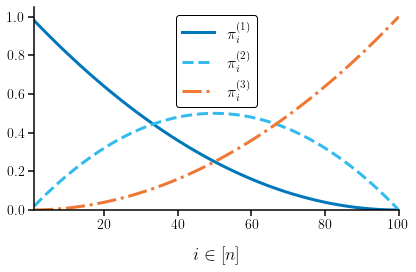

In [24]:
import numpy as np
import scipy.special
import matplotlib.pyplot as plt
# Assuming WERM is a custom module you have. If not, the code will use the binomial approximation.
# import WERM.config

def visualize_marginals_publication(pi_matrix, L, n):
    """
    Generates a publication-quality plot of marginal probabilities.

    Args:
        pi_matrix (np.ndarray): A (L x n) numpy array of marginal probabilities.
        L (int): The number of changepoints (rows in pi_matrix).
        n (int): The number of time points (columns in pi_matrix).
    """
    # --- 1. Apply Publication-Ready Style Configuration ---
    plt.rcParams.update({
        'font.size': 14,
        'font.family': 'serif',
        'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
        'text.usetex': True,
        'axes.linewidth': 1.5,
        'axes.labelsize': 18,
        'axes.titlesize': 20,
        'xtick.labelsize': 14,
        'ytick.labelsize': 14,
        'legend.fontsize': 16,
        'legend.frameon': True,
        'legend.fancybox': False,
        'legend.edgecolor': 'black',
        'legend.framealpha': 1.0,
        'lines.linewidth': 3.5,
        'lines.markersize': 8,
        'figure.dpi': 72,
        'savefig.dpi': 300,
        'savefig.bbox': 'tight',
        'savefig.pad_inches': 0.1
    })

    # --- 2. Define a Professional Color Palette ---
    # Using Paul Tol "Vibrant" for accessibility and aesthetics
    TOL_VIBRANT = ['#0077BB', '#33BBEE', '#EE7733', '#CC3311',
                   '#009988', '#BBBBBB', '#EE3377', '#DDAA33']

    markers = ['o', 's', 'D', '^', 'v', '>', '<', 'p', '*']
    line_styles = ['-', '--', '-.', ':']
    # --- 3. Create the Plot using Subplots for Better Control ---
    fig, ax = plt.subplots(figsize=(6, 4))

    # --- 4. Plot Each Marginal Probability with Enhanced Styling ---
    for l in range(L):
        ax.plot(
            np.arange(1, n + 1),  # X-axis should be from 1 to n
            pi_matrix[l, :],
            label=rf'$\pi^{{({l+1})}}_i$', # LaTeX label
            color=TOL_VIBRANT[l % len(TOL_VIBRANT)], # Cycle through palette
            linewidth=3.0,
            linestyle=line_styles[l % len(line_styles)],
        )

    # --- 5. Set Titles and Labels with LaTeX Formatting ---
    # ax.set_title(r'\textbf{Marginal Probabilities of Changepoint Rank}', pad=20)
    ax.set_xlabel(r'$i \in [n]$', labelpad=15)
    # ax.set_xticks(np.arange(1, n + 1, step=max(1, n // 3)))  # Set x-ticks for clarity
    # Set the x tick labels to be n/10, n/5, n/2, 3n/5, 4n/5, n
    # x_tick_labels = [f'n / {3-i}' for i in range(3)]
    # ax.set_xticklabels(x_tick_labels, rotation=45, ha='right')
    # ax.set_ylabel(r'$\pi_l(i)$', labelpad=15)  # Uncomment for LaTeX y-label
    # Uncomment the next line if you want to use a different y-label
    # ax.set_ylabel(r'$\pi_l(i)$', labelpad=
    # ax.set_ylabel(r'Probability $\pi_l(i)$', labelpad=15)

    # --- 6. Customize Axes and Legend ---
    ax.set_xlim(1, n)
    ax.set_ylim(bottom=0)
    
    # Customize spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Customize tick parameters
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    
    # Add a styled legend
    ax.legend(loc='best', fancybox=True)

    # --- 7. Final Touches ---
    plt.tight_layout()
    # plt.show()
    return fig, ax


# --- Main script logic to generate data and call the plotting function ---

# --- Parameters ---
L_is_upper_bound = False
n = 100
p = 400
delta_fraction = 1/10
# Delta_n = int(delta_fraction * n)
Delta_n = 1
L = 3

# --- Data Calculation (from your original script) ---
# This part remains unchanged.
pi = np.zeros((L, n))

if Delta_n == 1: # No separation, use binomial approximation
    print("Using Binomial Approximation for marginals...")
    if L_is_upper_bound:
        pi_i_l = lambda L, l, i: 1 / (L - l + 1) * np.sum([scipy.special.comb(k - 1, l - 1, exact=False) * (i/n)**(l - 1) * (1 - i/n)**(k - l) for k in range(l, L + 1)])
    else:
        pi_i_l = lambda L, l, i: scipy.special.comb(L - 1, l - 1, exact=False) * (i/n)**(l - 1) * (1 - i/n)**(L - l)

    for l in range(L):
        for i in range(n):
            pi[l, i] = pi_i_l(L, l + 1, i + 1)
else: # Use WERM for larger separation
    print("Using WERM for extrapolated marginals...")
    # This block requires the WERM library to be installed and configured.
    # Fallback to binomial if WERM is not available.
    try:
        import WERM.config
        n_small = 100
        Delta_n_small = int(Delta_n * n_small / n)
        p_l = 1/L * np.ones(L) if L_is_upper_bound else None
        Lmin = 1 if L_is_upper_bound else L
        Lmax = L
        pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small=n_small, n_large=n, p_l=p_l, verbose=False)
    except (ImportError, AttributeError):
        print("WERM library not found. Falling back to Binomial Approximation.")
        pi_i_l = lambda L, l, i: scipy.special.comb(L - 1, l - 1, exact=False) * (i/n)**(l - 1) * (1 - i/n)**(L - l)
        for l in range(L):
            for i in range(n):
                pi[l, i] = pi_i_l(L, l + 1, i + 1)


# --- Call the new publication-quality plotting function ---
fig, ax = visualize_marginals_publication(pi, L, n)
fig.savefig('figures/marginal_viz_L3_unif.pdf', bbox_inches='tight', dpi=300)
fig.savefig('figures/marginal_viz_L3_unif.pgf', bbox_inches='tight', dpi=300)
%matplotlib inline
plt.show()

# Two State L=3 viz

Using Binomial Approximation for marginals...


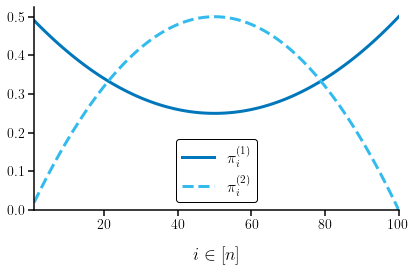

In [25]:
L_is_upper_bound = False
n = 100
p = 400
delta_fraction = 1/10
# Delta_n = int(delta_fraction * n)
Delta_n = 1
L = 3

# --- Data Calculation (from your original script) ---
# This part remains unchanged.
pi = np.zeros((L, n))

if Delta_n == 1: # No separation, use binomial approximation
    print("Using Binomial Approximation for marginals...")
    if L_is_upper_bound:
        pi_i_l = lambda L, l, i: 1 / (L - l + 1) * np.sum([scipy.special.comb(k - 1, l - 1, exact=False) * (i/n)**(l - 1) * (1 - i/n)**(k - l) for k in range(l, L + 1)])
    else:
        pi_i_l = lambda L, l, i: scipy.special.comb(L - 1, l - 1, exact=False) * (i/n)**(l - 1) * (1 - i/n)**(L - l)

    for l in range(L):
        for i in range(n):
            pi[l, i] = pi_i_l(L, l + 1, i + 1)
else: # Use WERM for larger separation
    print("Using WERM for extrapolated marginals...")
    # This block requires the WERM library to be installed and configured.
    # Fallback to binomial if WERM is not available.
    try:
        import WERM.config
        n_small = 100
        Delta_n_small = int(Delta_n * n_small / n)
        p_l = 1/L * np.ones(L) if L_is_upper_bound else None
        Lmin = 1 if L_is_upper_bound else L
        Lmax = L
        pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small=n_small, n_large=n, p_l=p_l, verbose=False)
    except (ImportError, AttributeError):
        print("WERM library not found. Falling back to Binomial Approximation.")
        pi_i_l = lambda L, l, i: scipy.special.comb(L - 1, l - 1, exact=False) * (i/n)**(l - 1) * (1 - i/n)**(L - l)
        for l in range(L):
            for i in range(n):
                pi[l, i] = pi_i_l(L, l + 1, i + 1)

pi_new = np.zeros((2, n))
pi_new[0, :] = (pi[0, :] + pi[2, :]) / 2
pi_new[1, :] = pi[1, :]


# --- Call the new publication-quality plotting function ---
fig, ax = visualize_marginals_publication(pi_new, 2, n)
fig.savefig('figures/marginal_viz_L3_twostate.pdf', bbox_inches='tight', dpi=300)
fig.savefig('figures/marginal_viz_L3_twostate.pgf', bbox_inches='tight', dpi=300)
%matplotlib inline
plt.show()